In [1]:
# Folders written by inter_heter_metrics.py (-out); change to wherever you saved the AoD CSVs
ROOT_DATA_OG = "RESULTS_HET/"           # tumor / stroma
ROOT_DATA_DIR = "RESULTS_BY_DENSITY/"   # TumorDense / TumorNotDense / StromaDense / StromaNotDense
print("Reading tumor/stroma data from: " + ROOT_DATA_OG)
print("Reading dense/not-dense data from: " + ROOT_DATA_DIR)

Reading tumor/stroma data from: RESULTS_HET/
Reading dense/not-dense data from: RESULTS_BY_DENSITY/


In [2]:
# Define plotting functions for 2, 3 and 4 simultaneous density plots
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def dataplot2(data1: pd.Series, data2: pd.Series,
              label1: str = '', label2: str = '', title: str =''):

    sns.kdeplot(data1, fill=True, color='navy', alpha=0.5, label=label1)
    sns.kdeplot(data2, fill=True, color='orange', alpha=0.5, label=label2)

    plt.title(title)
    plt.xlabel('Average of Distances')
    plt.ylabel('Density')
    plt.legend()
    plt.grid(True)

def dataplot3(data1: pd.Series, data2: pd.Series, data3: pd.Series,
              label1: str = '', label2: str = '', label3: str = '', title: str =''):
    sns.kdeplot(data1, fill=True, color='blue', alpha=0.5, label=label1)
    sns.kdeplot(data2, fill=True, color='orange', alpha=0.5, label=label2)
    sns.kdeplot(data3, fill=True, color='olive', alpha=0.5, label=label3)
    plt.title(title)
    plt.xlabel('Average of Distances')
    plt.ylabel('Density')
    plt.legend()
    plt.grid(True)

def dataplot4(data1: pd.Series, data2: pd.Series, data3: pd.Series, data4: pd.Series,
              label1: str = '', label2: str = '', label3: str = '', label4: str = '', title: str =''):
    sns.kdeplot(data1, fill=True, color='blue', alpha=0.5, label=label1)
    sns.kdeplot(data2, fill=True, color='orange', alpha=0.5, label=label2)
    sns.kdeplot(data3, fill=True, color='olive', alpha=0.5, label=label3)
    sns.kdeplot(data4, fill=True, color='lightcoral', alpha=0.5, label=label4)
    plt.title(title)
    plt.xlabel('Average of Distances')
    plt.ylabel('Density')
    plt.legend()
    plt.grid(True)


print("plotting functions have been defined.")

plotting functions have been defined.


In [3]:
tum_bmi_l = pd.read_csv(ROOT_DATA_OG + "aod_tumor_bmi-low.csv")
tum_bmi_h = pd.read_csv(ROOT_DATA_OG + "aod_tumor_bmi-high.csv")
str_bmi_l = pd.read_csv(ROOT_DATA_OG + "aod_stroma_bmi-low.csv")
str_bmi_h = pd.read_csv(ROOT_DATA_OG + "aod_stroma_bmi-high.csv")

In [4]:
# Read data

td_bmi_l = pd.read_csv(ROOT_DATA_DIR + "aod_TumorDense_bmi-low.csv")
td_bmi_h = pd.read_csv(ROOT_DATA_DIR + "aod_TumorDense_bmi-high.csv")
sd_bmi_l = pd.read_csv(ROOT_DATA_DIR + "aod_StromaDense_bmi-low.csv")
sd_bmi_h = pd.read_csv(ROOT_DATA_DIR + "aod_StromaDense_bmi-high.csv")
tn_bmi_l = pd.read_csv(ROOT_DATA_DIR + "aod_TumorNotDense_bmi-low.csv")
tn_bmi_h = pd.read_csv(ROOT_DATA_DIR + "aod_TumorNotDense_bmi-high.csv")
sn_bmi_l = pd.read_csv(ROOT_DATA_DIR + "aod_StromaNotDense_bmi-low.csv")
sn_bmi_h = pd.read_csv(ROOT_DATA_DIR + "aod_StromaNotDense_bmi-high.csv")

print("data has been loaded")

data has been loaded


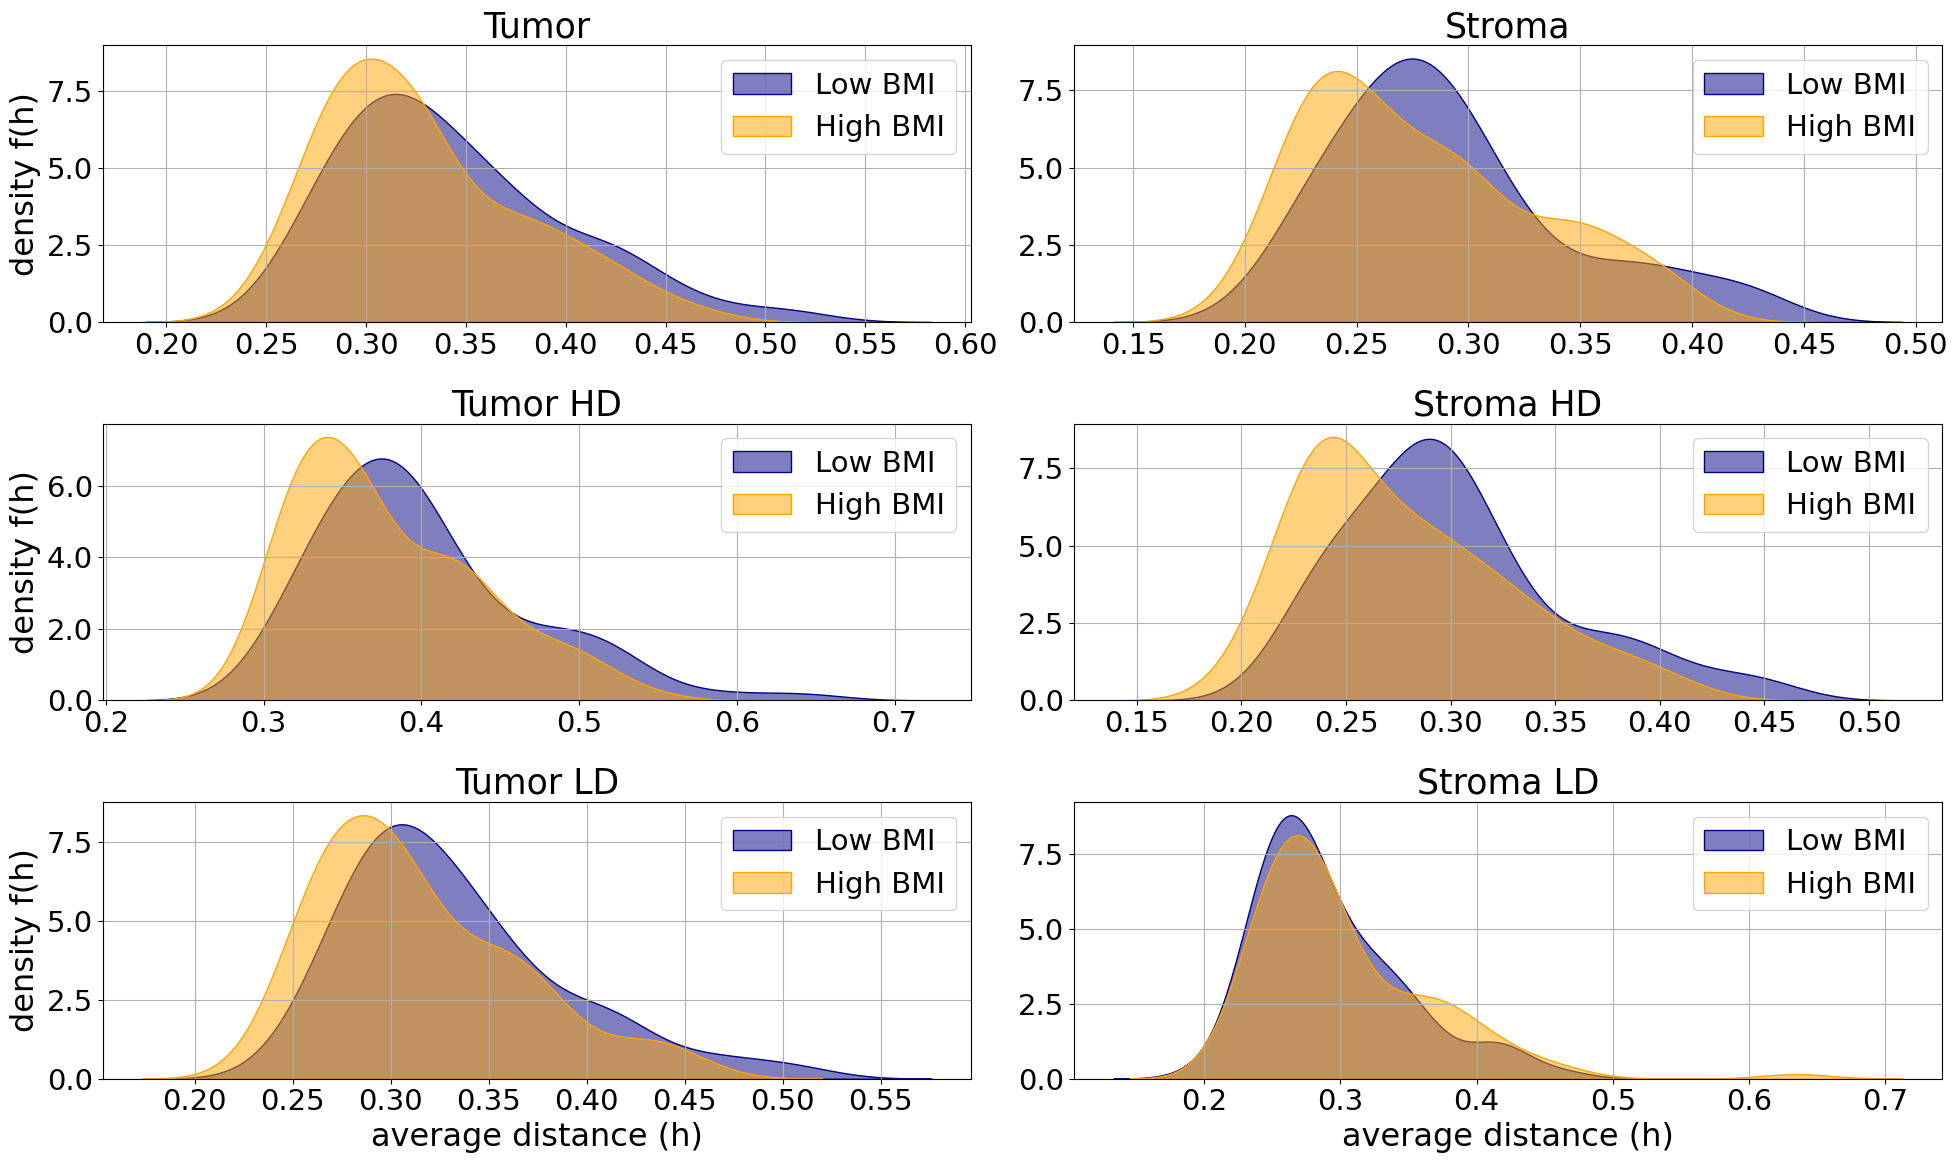

In [5]:
from matplotlib.ticker import FormatStrFormatter

plt.rcParams.update({
    'font.size': 19,
    'axes.titlesize': 25,
    'axes.labelsize': 23,
    'legend.fontsize': 21,
    'xtick.labelsize': 21,
    'ytick.labelsize': 21
})

fig, axes = plt.subplots(3, 2, figsize=(20,12))

# -------- Row 1 --------
plt.sca(axes[0, 0])
dataplot2(tum_bmi_l["aod"], tum_bmi_h["aod"],
          label1="Low BMI", label2="High BMI",
          title="Tumor")
axes[0, 0].set_ylabel("density f(h)")
axes[0, 0].set_xlabel("")

plt.sca(axes[0, 1])
dataplot2(str_bmi_l["aod"], str_bmi_h["aod"],
          label1="Low BMI", label2="High BMI",
          title="Stroma")
axes[0, 1].set_ylabel("")
axes[0, 1].set_xlabel("")

# -------- Row 2 --------
plt.sca(axes[1, 0])
dataplot2(td_bmi_l["aod"], td_bmi_h["aod"],
          label1="Low BMI", label2="High BMI",
          title="Tumor HD")
axes[1, 0].set_ylabel("density f(h)")
axes[1, 0].set_xlabel("")

plt.sca(axes[1, 1])
dataplot2(sd_bmi_l["aod"], sd_bmi_h["aod"],
          label1="Low BMI", label2="High BMI",
          title="Stroma HD")
axes[1, 1].set_ylabel("")
axes[1, 1].set_xlabel("")

# -------- Row 3 --------
plt.sca(axes[2, 0])
dataplot2(tn_bmi_l["aod"], tn_bmi_h["aod"],
          label1="Low BMI", label2="High BMI",
          title="Tumor LD")
axes[2, 0].set_ylabel("density f(h)")
axes[2, 0].set_xlabel("average distance (h)")

plt.sca(axes[2, 1])
dataplot2(sn_bmi_l["aod"], sn_bmi_h["aod"],
          label1="Low BMI", label2="High BMI",
          title="Stroma LD")
axes[2, 1].set_ylabel("")
axes[2, 1].set_xlabel("average distance (h)")

# ---- Force consistent 1-decimal y tick formatting ----
for ax in axes.flatten():
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))

plt.tight_layout()
plt.show()

In [6]:
# Perform a kolmgorov-smirnov test to check if the data comes from the same distribution (null hypothesis)
from scipy.stats import ks_2samp
import numpy as np
res1 = ks_2samp(tum_bmi_l["aod"], tum_bmi_h["aod"])
print("P-value comparing Tumor:", np.round(res1.pvalue, 3))
res3 = ks_2samp(td_bmi_l["aod"], td_bmi_h["aod"])
print("P-value comparing tumor HD:", np.round(res3.pvalue, 3))
res12 = ks_2samp(tn_bmi_l["aod"], tn_bmi_h["aod"])
print("P-value comparing tumor LD", np.round(res12.pvalue, 3))

res2 = ks_2samp(str_bmi_l["aod"], str_bmi_h["aod"])
print("P-value comparing stroma:", np.round(res2.pvalue, 3))
res11 = ks_2samp(sd_bmi_l["aod"], sd_bmi_h["aod"])
print("P-value comparing stroma HD:", np.round(res11.pvalue, 3))
res13 = ks_2samp(sn_bmi_l["aod"], sn_bmi_h["aod"])
print("P-value comparing stroma LD:", np.round(res13.pvalue, 3))



P-value comparing Tumor: 0.125
P-value comparing tumor HD: 0.029
P-value comparing tumor LD 0.027
P-value comparing stroma: 0.04
P-value comparing stroma HD: 0.001
P-value comparing stroma LD: 0.64
